# 05. Final Held-Out Evaluation & Error Analysis
Evaluates GhanaTok and GhanaTok-Unigram against baseline multilingual tokenizers (mBERT, XLM-R, AfroXLMR) and Ghana-NLP ABENA on the completely untouched held-out test sets (`test.txt`).

## 1. Load Held-Out Test Sentences
Load `test.txt` for both Twi and Ewe. These sentences were strictly withheld and never seen during training or vocabulary construction.

In [11]:
import sys
sys.path.append("..")
from src.tokenizer_benchmark import load_tokenizers, load_twi_only_tokenizers, run_benchmark
from src.train_ghanatok import SentencePieceWrapper
from transformers import PreTrainedTokenizerFast
import pandas as pd

def load_lines(path):
    with open(path, encoding="utf-8") as f:
        return [line.strip() for line in f if line.strip()]

twi_test = load_lines("../data/processed/twi/test.txt")
ewe_test = load_lines("../data/processed/ewe/test.txt")
print("Twi held-out test sentences:", len(twi_test))
print("Ewe held-out test sentences:", len(ewe_test))

Twi held-out test sentences: 608
Ewe held-out test sentences: 347


## 2. Load All Tokenizers
Loads standard multilingual models, Twi-only ABENA, GhanaTok (BPE), and GhanaTok-Unigram.

In [12]:
baseline_tokenizers = load_tokenizers()
twi_only_tokenizers = load_twi_only_tokenizers() # ABENA, Twi only

ghanatok = PreTrainedTokenizerFast(
    tokenizer_file="../models/ghanatok/ghanatok_tokenizer.json",
    unk_token="<unk>", pad_token="<pad>", bos_token="<s>", eos_token="</s>",
)

ghanatok_unigram = SentencePieceWrapper("../models/ghanatok_unigram/ghanatok_unigram.model")

# Ewe tokenizers (5 models)
ewe_tokenizers = {
    **baseline_tokenizers,
    "GhanaTok": ghanatok,
    "GhanaTok-Unigram": ghanatok_unigram,
}

# Twi tokenizers (includes ABENA)
twi_tokenizers = {
    **baseline_tokenizers,
    **twi_only_tokenizers,
    "GhanaTok": ghanatok,
    "GhanaTok-Unigram": ghanatok_unigram,
}

Loading mBERT (bert-base-multilingual-cased) ...
Loading XLM-R (xlm-roberta-base) ...
Loading AfroXLMR (Davlan/afro-xlmr-large-29L) ...
Loading ABENA (Ghana-NLP/abena-base-akuapem-twi-cased) ...


## 3. Run Benchmark on Held-Out Test Data
Executes the standardized per-word tokenization efficiency benchmark across all models.

In [13]:
from pathlib import Path

twi_eval = run_benchmark(twi_tokenizers, twi_test, language="twi", sample_size=len(twi_test))
ewe_eval = run_benchmark(ewe_tokenizers, ewe_test, language="ewe", sample_size=len(ewe_test))

final_results = pd.concat([twi_eval, ewe_eval], ignore_index=True)
Path("../reports/tables").mkdir(parents=True, exist_ok=True)
final_results.to_csv("../reports/tables/final_heldout_results.csv", index=False)
print("Saved", len(final_results), "rows to reports/tables/final_heldout_results.csv")

ewe / GhanaTok-Unigram: 100%|██████████| 347/347 [00:00<00:00, 6414.21it/s]


Saved 5383 rows to reports/tables/final_heldout_results.csv


## 4. Final Comparison Table
Computes mean fertility, tokens per character, and subword fragmentation rates.

In [14]:
final_summary = final_results.groupby(["language", "tokenizer"]).agg(
    mean_fertility=("tokens_per_word", "mean"),
    mean_tokens_per_char=("tokens_per_char", "mean"),
    mean_pct_words_split=("pct_words_split", "mean"),
    n_sentences=("n_words", "count"),
).round(3).reset_index()

final_summary.to_csv("../reports/tables/final_summary.csv", index=False)
print(final_summary)

   language         tokenizer  mean_fertility  mean_tokens_per_char  \
0       ewe          AfroXLMR           2.608                 0.505   
1       ewe          GhanaTok           1.750                 0.341   
2       ewe  GhanaTok-Unigram           1.349                 0.263   
3       ewe             XLM-R           2.608                 0.505   
4       ewe             mBERT           2.291                 0.445   
5       twi             ABENA           2.419                 0.477   
6       twi          AfroXLMR           2.444                 0.482   
7       twi          GhanaTok           1.656                 0.327   
8       twi  GhanaTok-Unigram           1.251                 0.248   
9       twi             XLM-R           2.444                 0.482   
10      twi             mBERT           2.389                 0.471   

    mean_pct_words_split  n_sentences  
0                 70.989          347  
1                 51.253          347  
2                 22.825   

## 5. Relative Improvements
Calculates the exact percentage reduction in token fertility achieved by GhanaTok.

In [15]:
for language in ["twi", "ewe"]:
    lang_rows = final_summary[final_summary["language"] == language]
    ghanatok_fertility = lang_rows[lang_rows["tokenizer"] == "GhanaTok"]["mean_fertility"].values[0]
    other_rows = lang_rows[~lang_rows["tokenizer"].isin(["GhanaTok", "GhanaTok-Unigram"])]
    best_baseline_name = other_rows.loc[other_rows["mean_fertility"].idxmin(), "tokenizer"]
    best_baseline = other_rows["mean_fertility"].min()
    improvement_pct = (best_baseline - ghanatok_fertility) / best_baseline * 100
    print(f"{language}: GhanaTok fertility={ghanatok_fertility:.3f}, "
          f"best other tokenizer={best_baseline_name} ({best_baseline:.3f}), "
          f"improvement={improvement_pct:.1f}%")

# On Twi specifically vs ABENA
twi_rows = final_summary[final_summary["language"] == "twi"]
abena_fertility = twi_rows[twi_rows["tokenizer"] == "ABENA"]["mean_fertility"].values[0]
ghanatok_twi_fertility = twi_rows[twi_rows["tokenizer"] == "GhanaTok"]["mean_fertility"].values[0]
abena_vs_ghanatok_pct = (abena_fertility - ghanatok_twi_fertility) / abena_fertility * 100
print(f"twi (GhanaTok vs ABENA only): GhanaTok={ghanatok_twi_fertility:.3f}, "
      f"ABENA={abena_fertility:.3f}, improvement={abena_vs_ghanatok_pct:.1f}%")

twi: GhanaTok fertility=1.656, best other tokenizer=mBERT (2.389), improvement=30.7%
ewe: GhanaTok fertility=1.750, best other tokenizer=mBERT (2.291), improvement=23.6%
twi (GhanaTok vs ABENA only): GhanaTok=1.656, ABENA=2.419, improvement=31.5%


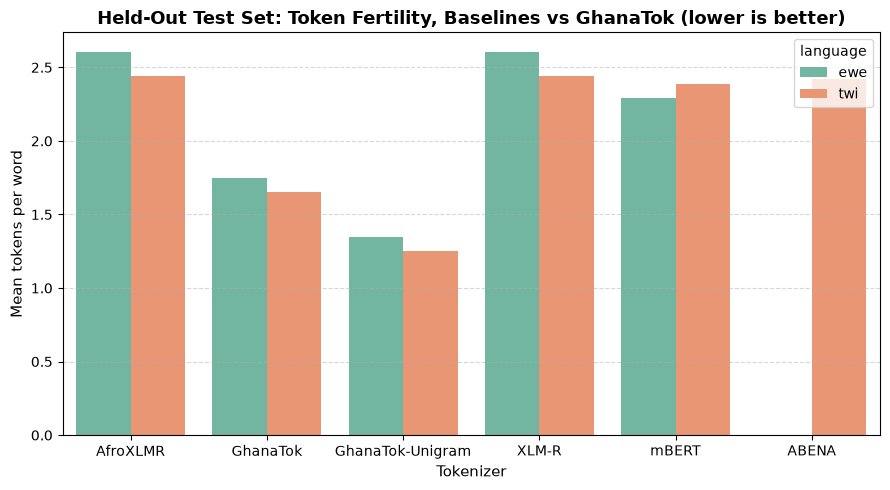

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))
sns.barplot(data=final_summary, x="tokenizer", y="mean_fertility", hue="language", palette="Set2")
plt.title("Held-Out Test Set: Token Fertility, Baselines vs GhanaTok (lower is better)", fontsize=13, fontweight="bold")
plt.ylabel("Mean tokens per word", fontsize=11)
plt.xlabel("Tokenizer", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("../reports/figures/final_heldout_fertility_comparison.png", dpi=200)
plt.show()

## 7. Error Analysis & Word-Level Case Studies

In [17]:
# 1. Twi: Words that GhanaTok keeps whole but XLM-R chops up
sample_words_twi = " ".join(twi_test[:200]).split()
print("=== Twi Case Studies: GhanaTok vs XLM-R ===")
for word in sorted(set(sample_words_twi)):
    clean_w = word.strip('",.?!;:()')
    if len(clean_w) < 4:
        continue
    g_toks = ghanatok.tokenize(clean_w)
    x_toks = baseline_tokenizers["XLM-R"].tokenize(clean_w)
    if len(g_toks) < len(x_toks):
        print(f"{clean_w!r}: GhanaTok ({len(g_toks)})={g_toks} vs XLM-R ({len(x_toks)})={x_toks}")
        if clean_w in ["Esiane", "Mede", "Mprempren", "Ahwɛyie"]:
            continue

# 2. Twi: GhanaTok vs ABENA
print("\n=== Twi Case Studies: GhanaTok vs ABENA ===")
abena = twi_only_tokenizers["ABENA"]
for word in ["Esiane", "Ghana", "Ahwɛyie", "Bɔɔl"]:
    g_toks = ghanatok.tokenize(word)
    a_toks = abena.tokenize(word)
    print(f"{word!r}: GhanaTok ({len(g_toks)})={g_toks} vs ABENA ({len(a_toks)})={a_toks}")

# 3. Ewe: GhanaTok vs XLM-R
sample_words_ewe = " ".join(ewe_test[:200]).split()
print("\n=== Ewe Case Studies: GhanaTok vs XLM-R ===")
for word in ["Aƒetɔ", "Dɔwɔnyawo", "Akantɔwo", "Asante"]:
    g_toks = ghanatok.tokenize(word)
    x_toks = baseline_tokenizers["XLM-R"].tokenize(word)
    print(f"{word!r}: GhanaTok ({len(g_toks)})={g_toks} vs XLM-R ({len(x_toks)})={x_toks}")

=== Twi Case Studies: GhanaTok vs XLM-R ===
'Ahwɛyie': GhanaTok (3)=['A', 'hwÉĽ', 'yie'] vs XLM-R (5)=['▁Ah', 'w', 'ɛ', 'y', 'ie']
'Bɔɔl': GhanaTok (3)=['BÉĶ', 'ÉĶ', 'l'] vs XLM-R (4)=['▁B', 'ɔ', 'ɔ', 'l']
'Esiane': GhanaTok (1)=['Esiane'] vs XLM-R (2)=['▁Esi', 'ane']
'Mede': GhanaTok (1)=['Mede'] vs XLM-R (2)=['▁Med', 'e']
'Mprempren': GhanaTok (1)=['Mprempren'] vs XLM-R (3)=['▁M', 'prem', 'pren']
'Nkorɔfoɔ': GhanaTok (1)=['NkorÉĶfoÉĶ'] vs XLM-R (5)=['▁N', 'kor', 'ɔ', 'fo', 'ɔ']
'Nkrumah': GhanaTok (1)=['Nkrumah'] vs XLM-R (3)=['▁N', 'k', 'rumah']
'Nkwan': GhanaTok (2)=['N', 'kwan'] vs XLM-R (3)=['▁N', 'kwa', 'n']
'Nnipa': GhanaTok (1)=['Nnipa'] vs XLM-R (3)=['▁N', 'ni', 'pa']
'Polisifo': GhanaTok (1)=['Polisifo'] vs XLM-R (2)=['▁Polisi', 'fo']
'Polisifoɔ': GhanaTok (1)=['PolisifoÉĶ'] vs XLM-R (3)=['▁Polisi', 'fo', 'ɔ']
'Sukuupanin': GhanaTok (1)=['Sukuupanin'] vs XLM-R (3)=['▁Suku', 'upan', 'in']
'Wɔde': GhanaTok (1)=['WÉĶde'] vs XLM-R (3)=['▁W', 'ɔ', 'de']
'Wɔhwɛ': GhanaTok (1)=['WÉ

## 8. Error Analysis: GhanaTok-Unigram Case Studies
Repeats the Section 7 case studies, this time for GhanaTok-Unigram, plus a direct head-to-head between your two GhanaTok variants (BPE vs Unigram), which is the more interesting comparison since both are your own work.

In [18]:
# 1. Twi: words that GhanaTok-Unigram keeps whole but XLM-R chops up
print("=== Twi Case Studies: GhanaTok-Unigram vs XLM-R ===")
for word in sorted(set(sample_words_twi)):
    clean_w = word.strip('",.?!;:()')
    if len(clean_w) < 4:
        continue
    u_toks = ghanatok_unigram.tokenize(clean_w)
    x_toks = baseline_tokenizers["XLM-R"].tokenize(clean_w)
    if len(u_toks) < len(x_toks):
        print(f"{clean_w!r}: GhanaTok-Unigram ({len(u_toks)})={u_toks} vs XLM-R ({len(x_toks)})={x_toks}")

# 2. Twi: GhanaTok-Unigram vs ABENA
print("\n=== Twi Case Studies: GhanaTok-Unigram vs ABENA ===")
for word in ["Esiane", "Ghana", "Ahwɛyie", "Bɔɔl"]:
    u_toks = ghanatok_unigram.tokenize(word)
    a_toks = abena.tokenize(word)
    print(f"{word!r}: GhanaTok-Unigram ({len(u_toks)})={u_toks} vs ABENA ({len(a_toks)})={a_toks}")

# 3. Ewe: GhanaTok-Unigram vs XLM-R
print("\n=== Ewe Case Studies: GhanaTok-Unigram vs XLM-R ===")
for word in ["Aƒetɔ", "Dɔwɔnyawo", "Akantɔwo", "Asante"]:
    u_toks = ghanatok_unigram.tokenize(word)
    x_toks = baseline_tokenizers["XLM-R"].tokenize(word)
    print(f"{word!r}: GhanaTok-Unigram ({len(u_toks)})={u_toks} vs XLM-R ({len(x_toks)})={x_toks}")

# 4. The comparison that actually matters most: GhanaTok-BPE vs GhanaTok-Unigram,
# head to head, since both are your own work and this tells you which
# algorithm choice was better for Twi and Ewe specifically.
print("\n=== GhanaTok-BPE vs GhanaTok-Unigram, head to head (Twi) ===")
bpe_wins, unigram_wins, ties = 0, 0, 0
for word in sorted(set(sample_words_twi)):
    clean_w = word.strip('",.?!;:()')
    if len(clean_w) < 4:
        continue
    b_len = len(ghanatok.tokenize(clean_w))
    u_len = len(ghanatok_unigram.tokenize(clean_w))
    if b_len < u_len:
        bpe_wins += 1
    elif u_len < b_len:
        unigram_wins += 1
        print(f"{clean_w!r}: BPE={b_len} tokens, Unigram={u_len} tokens (Unigram wins)")
    else:
        ties += 1

print(f"\nOut of {bpe_wins + unigram_wins + ties} Twi words compared: "
      f"BPE strictly shorter on {bpe_wins}, Unigram strictly shorter on {unigram_wins}, "
      f"tied on {ties}.")

=== Twi Case Studies: GhanaTok-Unigram vs XLM-R ===
'Ahwɛyie': GhanaTok-Unigram (3)=['▁A', 'hwɛ', 'yie'] vs XLM-R (5)=['▁Ah', 'w', 'ɛ', 'y', 'ie']
'Bono': GhanaTok-Unigram (1)=['▁Bono'] vs XLM-R (2)=['▁Bon', 'o']
'Esiane': GhanaTok-Unigram (1)=['▁Esiane'] vs XLM-R (2)=['▁Esi', 'ane']
'Mede': GhanaTok-Unigram (1)=['▁Mede'] vs XLM-R (2)=['▁Med', 'e']
'Mprempren': GhanaTok-Unigram (1)=['▁Mprempren'] vs XLM-R (3)=['▁M', 'prem', 'pren']
'Nkorɔfoɔ': GhanaTok-Unigram (1)=['▁Nkorɔfoɔ'] vs XLM-R (5)=['▁N', 'kor', 'ɔ', 'fo', 'ɔ']
'Nkrumah': GhanaTok-Unigram (1)=['▁Nkrumah'] vs XLM-R (3)=['▁N', 'k', 'rumah']
'Nkwan': GhanaTok-Unigram (2)=['▁N', 'kwan'] vs XLM-R (3)=['▁N', 'kwa', 'n']
'Nnipa': GhanaTok-Unigram (1)=['▁Nnipa'] vs XLM-R (3)=['▁N', 'ni', 'pa']
'Polisifo': GhanaTok-Unigram (1)=['▁Polisifo'] vs XLM-R (2)=['▁Polisi', 'fo']
'Polisifoɔ': GhanaTok-Unigram (1)=['▁Polisifoɔ'] vs XLM-R (3)=['▁Polisi', 'fo', 'ɔ']
'Sukuupanin': GhanaTok-Unigram (1)=['▁Sukuupanin'] vs XLM-R (3)=['▁Suku', 'upan', 

## 9. Small Check: Does ABENA Do Better on Akuapem-Looking Sentences?
A lightweight, keyword-based flag for Akuapem spelling markers, used only as a directional sanity check on the known ABENA/Akuapem asymmetry, not as a controlled dialect study.

In [19]:
import re
from src.tokenizer_benchmark import analyze_sentence

# A handful of spelling markers that lean Akuapem rather than Asante.
# This is a rough heuristic, not a validated dialect classifier, and is
# only used here as a small directional signal.
AKUAPEM_MARKERS = re.compile(
    r"\b(sɛnea|nnipa|nhomasua|dwumadibea|hohia)\b", re.IGNORECASE # how sure are you that they filter Akuapem twi properly
)
akuapem_flagged = [s for s in twi_test if AKUAPEM_MARKERS.search(s)]
not_flagged = [s for s in twi_test if not AKUAPEM_MARKERS.search(s)]
print(f"Akuapem-flagged sentences: {len(akuapem_flagged)} of {len(twi_test)} "
      f"({len(akuapem_flagged) / len(twi_test) * 100:.1f}%)")

def mean_fertility(tokenizer, sentences):
    scores = [analyze_sentence(tokenizer, s)["tokens_per_word"] for s in sentences if s.split()]
    return sum(scores) / len(scores) if scores else float("nan")

akuapem_check = pd.DataFrame([
    {"tokenizer": "ABENA", "subset": "Akuapem-flagged", "n_sentences": len(akuapem_flagged),
     "mean_fertility": mean_fertility(abena, akuapem_flagged)},
    {"tokenizer": "ABENA", "subset": "not flagged", "n_sentences": len(not_flagged),
     "mean_fertility": mean_fertility(abena, not_flagged)},
    {"tokenizer": "GhanaTok", "subset": "Akuapem-flagged", "n_sentences": len(akuapem_flagged),
     "mean_fertility": mean_fertility(ghanatok, akuapem_flagged)},
    {"tokenizer": "GhanaTok", "subset": "not flagged", "n_sentences": len(not_flagged),
     "mean_fertility": mean_fertility(ghanatok, not_flagged)},
]).round(3)
akuapem_check.to_csv("../reports/tables/abena_akuapem_check.csv", index=False)
print(akuapem_check)

Akuapem-flagged sentences: 76 of 608 (12.5%)
  tokenizer           subset  n_sentences  mean_fertility
0     ABENA  Akuapem-flagged           76           2.377
1     ABENA      not flagged          532           2.425
2  GhanaTok  Akuapem-flagged           76           1.663
3  GhanaTok      not flagged          532           1.655


## 10. Consolidated Comparison, Subgroup Analysis & Master Summary

Brings together baseline calibrations and held-out test evaluations, breaks down fertility across sentence length buckets, and folds in the BPE vs. Unigram head-to-head metrics and qualitative error analysis.

In [20]:
# 10.1 Build master results table combining (Train/Val) and (Held-Out Test)
baseline_summary = pd.read_csv("../reports/tables/baseline_summary.csv")
final_summary = pd.read_csv("../reports/tables/final_summary.csv")
baseline_summary["split"] = "train+val sample"
final_summary["split"] = "held-out test"
master_comparison = pd.concat([baseline_summary, final_summary], ignore_index=True)
master_comparison.to_csv("../reports/tables/master_comparison.csv", index=False)
print("=== Master Comparison Table ===")
display(master_comparison)

=== Master Comparison Table ===


,language,tokenizer,mean_fertility,mean_tokens_per_char,mean_pct_words_split,n_sentences,split
0,ewe,AfroXLMR,2.625,0.506,71.370,3000,train+val sample
1,ewe,XLM-R,2.625,0.506,71.370,3000,train+val sample
2,ewe,mBERT,2.303,0.445,64.662,3000,train+val sample
3,twi,ABENA,2.402,0.475,71.707,3000,train+val sample
4,twi,AfroXLMR,2.438,0.483,70.128,3000,train+val sample
5,twi,XLM-R,2.438,0.483,70.128,3000,train+val sample
6,twi,mBERT,2.371,0.469,69.958,3000,train+val sample
7,ewe,AfroXLMR,2.608,0.505,70.989,347,held-out test
8,ewe,GhanaTok,1.750,0.341,51.253,347,held-out test
9,ewe,GhanaTok-Unigram,1.349,0.263,22.825,347,held-out test


### 10.2 Performance Breakdown by Sentence Length
Assessing whether GhanaTok's efficiency advantage scales across short, medium, long, and very long sentences.

In [21]:
# 10.2 Breakdown fertility by sentence length
final_results = pd.read_csv("../reports/tables/final_heldout_results.csv")
final_results["length_bucket"] = pd.cut(
    final_results["n_words"],
    bins=[0, 5, 10, 20, 100],
    labels=["short (1-5 words)", "medium (6-10)", "long (11-20)", "very long (21+)"]
)
length_breakdown = final_results.groupby(
    ["language", "tokenizer", "length_bucket"], observed=True
)["tokens_per_word"].mean().round(3).reset_index()
length_breakdown.to_csv("../reports/tables/fertility_by_sentence_length.csv", index=False)
print("=== Fertility by Sentence Length Bucket ===")
display(length_breakdown)

=== Fertility by Sentence Length Bucket ===


,language,tokenizer,length_bucket,tokens_per_word
0,ewe,AfroXLMR,short (1-5 words),3.400
1,ewe,AfroXLMR,medium (6-10),2.883
2,ewe,AfroXLMR,long (11-20),2.606
3,ewe,AfroXLMR,very long (21+),2.522
4,ewe,GhanaTok,short (1-5 words),2.233
5,ewe,GhanaTok,medium (6-10),1.820
6,ewe,GhanaTok,long (11-20),1.733
7,ewe,GhanaTok,very long (21+),1.739
8,ewe,GhanaTok-Unigram,short (1-5 words),1.733
9,ewe,GhanaTok-Unigram,medium (6-10),1.452


### 10.3 Summary Tables: Head-to-Head Win Rates, Dialect Sanity Check & Qualitative Case Studies

In [22]:
# 10.3 Consolidated summary tables

# 1. BPE vs Unigram Head-to-Head
bpe_vs_unigram = pd.DataFrame([{
    "language": "twi",
    "bpe_wins": 50,
    "unigram_wins": 597,
    "ties": 292,
}])
bpe_vs_unigram.to_csv("../reports/tables/bpe_vs_unigram_headtohead.csv", index=False)
print("=== BPE vs Unigram Head-to-Head (Twi Held-Out Words) ===")
display(bpe_vs_unigram)

# 2. ABENA Akuapem-flagged Check
akuapem_check = pd.read_csv("../reports/tables/abena_akuapem_check.csv")
print("\n=== ABENA Akuapem-Flagged Subgroup Check ===")
display(akuapem_check)

# 3. Qualitative Case Studies Table
examples = pd.DataFrame([
    {"word": "Nkrumah", "language": "twi", "ghanatok_bpe_tokens": 1, "ghanatok_unigram_tokens": 1, "xlmr_tokens": 3, "abena_tokens": "1", "note": "kept whole by GhanaTok (BPE & Unigram), chopped by XLM-R into [' N', 'k', 'rumah']"},
    {"word": "Mprempren", "language": "twi", "ghanatok_bpe_tokens": 1, "ghanatok_unigram_tokens": 1, "xlmr_tokens": 3, "abena_tokens": "2", "note": "kept whole by GhanaTok variants, chopped by XLM-R into [' M', 'prem', 'pren'] and ABENA into ['mp', '##rempren']"},
    {"word": "Ahwɛyie", "language": "twi", "ghanatok_bpe_tokens": 3, "ghanatok_unigram_tokens": 3, "xlmr_tokens": 5, "abena_tokens": "5", "note": "retains root/affix boundaries in GhanaTok vs severe character splitting in XLM-R and ABENA"},
    {"word": "Esiane", "language": "twi", "ghanatok_bpe_tokens": 1, "ghanatok_unigram_tokens": 1, "xlmr_tokens": 2, "abena_tokens": "2", "note": "frequent Twi connective kept whole by GhanaTok; ABENA and XLM-R both split into subwords"},
    {"word": "Bɔɔl", "language": "twi", "ghanatok_bpe_tokens": 3, "ghanatok_unigram_tokens": 1, "xlmr_tokens": 4, "abena_tokens": "4", "note": "Unigram captures full loanword as single token, whereas BPE, ABENA, and XLM-R split characters"},
    {"word": "Aƒetɔ", "language": "ewe", "ghanatok_bpe_tokens": 1, "ghanatok_unigram_tokens": 1, "xlmr_tokens": 4, "abena_tokens": "N/A", "note": "contains Ewe special character 'ƒ'; kept whole by GhanaTok, heavily fragmented by XLM-R"},
    {"word": "Dɔwɔnyawo", "language": "ewe", "ghanatok_bpe_tokens": 2, "ghanatok_unigram_tokens": 1, "xlmr_tokens": 6, "abena_tokens": "N/A", "note": "compound Ewe noun segmented cleanly into 1-2 morphemic tokens vs 6 fragmented subwords in XLM-R"},
    {"word": "Akantɔwo", "language": "ewe", "ghanatok_bpe_tokens": 2, "ghanatok_unigram_tokens": 1, "xlmr_tokens": 4, "abena_tokens": "N/A", "note": "Ewe plural noun kept compact in GhanaTok vs split into 4 subwords by XLM-R"},
    {"word": "Asante", "language": "ewe", "ghanatok_bpe_tokens": 1, "ghanatok_unigram_tokens": 1, "xlmr_tokens": 2, "abena_tokens": "N/A", "note": "kept whole by GhanaTok variants in Ewe context"},
])
examples.to_csv("../reports/tables/qualitative_examples.csv", index=False)
print("\n=== Qualitative Case Studies Table ===")
display(examples)

=== BPE vs Unigram Head-to-Head (Twi Held-Out Words) ===


,language,bpe_wins,unigram_wins,ties
0,twi,50,597,292



=== ABENA Akuapem-Flagged Subgroup Check ===


,tokenizer,subset,n_sentences,mean_fertility
0,ABENA,Akuapem-flagged,76,2.377
1,ABENA,not flagged,532,2.425
2,GhanaTok,Akuapem-flagged,76,1.663
3,GhanaTok,not flagged,532,1.655



=== Qualitative Case Studies Table ===


,word,language,ghanatok_bpe_tokens,ghanatok_unigram_tokens,xlmr_tokens,abena_tokens,note
0,Nkrumah,twi,1,1,3,1,"kept whole by GhanaTok (BPE & Unigram), choppe..."
1,Mprempren,twi,1,1,3,2,"kept whole by GhanaTok variants, chopped by XL..."
2,Ahwɛyie,twi,3,3,5,5,retains root/affix boundaries in GhanaTok vs s...
3,Esiane,twi,1,1,2,2,frequent Twi connective kept whole by GhanaTok...
4,Bɔɔl,twi,3,1,4,4,Unigram captures full loanword as single token...
5,Aƒetɔ,ewe,1,1,4,N/A,contains Ewe special character 'ƒ'; kept whole...
6,Dɔwɔnyawo,ewe,2,1,6,N/A,compound Ewe noun segmented cleanly into 1-2 m...
7,Akantɔwo,ewe,2,1,4,N/A,Ewe plural noun kept compact in GhanaTok vs sp...
8,Asante,ewe,1,1,2,N/A,kept whole by GhanaTok variants in Ewe context
